# Notebook 2: Data Merging and Exploratory Data Analysis (EDA)

## Objective
Merge all 8 CICIDS2017 CSV files into a single dataset and explore its structure, feature distributions, class labels, and data-quality issues without performing data cleaning.

In [1]:
# Cell 1: Import required libraries

import os
import glob
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("default")

# Display settings
pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)
pd.set_option("display.width", 120)

# Visualization settings
sns.set_theme(style="whitegrid")

print("Libraries imported successfully.")
print("Pandas version:", pd.__version__)
print("NumPy version:", np.__version__)

Libraries imported successfully.
Pandas version: 3.0.6
NumPy version: 2.5.4


In [3]:
 # Locate raw CSV files in the correct directory

raw_data_path = os.path.join("..", "data", "raw", "cicids2017")

csv_files = sorted(
    glob.glob(os.path.join(raw_data_path, "*.csv"))
)

print("Raw data directory:", os.path.abspath(raw_data_path))
print("Number of CSV files found:", len(csv_files))

print("\nCSV files:")
for i, file in enumerate(csv_files, start=1):
    print(f"{i}. {os.path.basename(file)}")

Raw data directory: d:\ThreatTrace\data\raw\cicids2017
Number of CSV files found: 8

CSV files:
1. Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv
2. Friday-WorkingHours-Afternoon-PortScan.pcap_ISCX.csv
3. Friday-WorkingHours-Morning.pcap_ISCX.csv
4. Monday-WorkingHours.pcap_ISCX.csv
5. Thursday-WorkingHours-Afternoon-Infilteration.pcap_ISCX.csv
6. Thursday-WorkingHours-Morning-WebAttacks.pcap_ISCX.csv
7. Tuesday-WorkingHours.pcap_ISCX.csv
8. Wednesday-workingHours.pcap_ISCX.csv


In [ ]:
# Inspect CSV file sizes

file_info = []

for file in csv_files:
    size_mb = os.path.getsize(file) / (1024 ** 2)

    file_info.append({
        "File Name": os.path.basename(file),
        "Size (MB)": round(size_mb, 2)
    })

file_info_df = pd.DataFrame(file_info)

print("CSV File Size Summary:\n")
display(file_info_df)

total_size_mb = file_info_df["Size (MB)"].sum()

print(f"\nTotal size of all 8 CSV files: {total_size_mb:.2f} MB")

CSV File Size Summary:



,File Name,Size (MB)
0,Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv,73.55
1,Friday-WorkingHours-Afternoon-PortScan.pcap_IS...,73.34
2,Friday-WorkingHours-Morning.pcap_ISCX.csv,55.62
3,Monday-WorkingHours.pcap_ISCX.csv,168.73
4,Thursday-WorkingHours-Afternoon-Infilteration....,79.25
5,Thursday-WorkingHours-Morning-WebAttacks.pcap_...,49.61
6,Tuesday-WorkingHours.pcap_ISCX.csv,128.82
7,Wednesday-workingHours.pcap_ISCX.csv,214.74



Total size of all 8 CSV files: 843.66 MB


In [5]:
#  Load and merge all 8 CSV files

dataframes = []
file_row_counts = []

for file in csv_files:
    print(f"Loading: {os.path.basename(file)}")

    temp_df = pd.read_csv(
        file,
        low_memory=False
    )

    # Record the original row count for each file
    file_row_counts.append({
        "File Name": os.path.basename(file),
        "Rows": len(temp_df),
        "Columns": len(temp_df.columns)
    })

    dataframes.append(temp_df)

    print(f"Rows loaded: {len(temp_df):,}")

# Merge all files row-wise
df = pd.concat(
    dataframes,
    axis=0,
    ignore_index=True
)

print("\nAll files loaded and merged successfully.")
print(f"Total rows: {len(df):,}")
print(f"Total columns: {len(df.columns):,}")

Loading: Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv
Rows loaded: 225,745
Loading: Friday-WorkingHours-Afternoon-PortScan.pcap_ISCX.csv
Rows loaded: 286,467
Loading: Friday-WorkingHours-Morning.pcap_ISCX.csv
Rows loaded: 191,033
Loading: Monday-WorkingHours.pcap_ISCX.csv
Rows loaded: 529,918
Loading: Thursday-WorkingHours-Afternoon-Infilteration.pcap_ISCX.csv
Rows loaded: 288,602
Loading: Thursday-WorkingHours-Morning-WebAttacks.pcap_ISCX.csv
Rows loaded: 170,366
Loading: Tuesday-WorkingHours.pcap_ISCX.csv
Rows loaded: 445,909
Loading: Wednesday-workingHours.pcap_ISCX.csv
Rows loaded: 692,703

All files loaded and merged successfully.
Total rows: 2,830,743
Total columns: 79


In [6]:
#  Verify merged dataset dimensions and structure

print("MERGED DATASET OVERVIEW")
print("-" * 40)

print(f"Total rows: {df.shape[0]:,}")
print(f"Total columns: {df.shape[1]}")

print("\nDataset memory usage:")
print(f"{df.memory_usage(deep=True).sum() / (1024**3):.2f} GB")

print("\nDataFrame index:")
print(f"Index starts at: {df.index.min():,}")
print(f"Index ends at: {df.index.max():,}")

print("\nFirst 5 rows:")
display(df.head())

print("\nLast 5 rows:")
display(df.tail())

MERGED DATASET OVERVIEW
----------------------------------------
Total rows: 2,830,743
Total columns: 79

Dataset memory usage:
1.79 GB

DataFrame index:
Index starts at: 0
Index ends at: 2,830,742

First 5 rows:


,Destination Port,Flow Duration,Total Fwd Packets,Total Backward Packets,Total Length of Fwd Packets,Total Length of Bwd Packets,Fwd Packet Length Max,Fwd Packet Length Min,Fwd Packet Length Mean,Fwd Packet Length Std,Bwd Packet Length Max,Bwd Packet Length Min,Bwd Packet Length Mean,Bwd Packet Length Std,Flow Bytes/s,Flow Packets/s,Flow IAT Mean,Flow IAT Std,Flow IAT Max,Flow IAT Min,Fwd IAT Total,Fwd IAT Mean,Fwd IAT Std,Fwd IAT Max,Fwd IAT Min,Bwd IAT Total,Bwd IAT Mean,Bwd IAT Std,Bwd IAT Max,Bwd IAT Min,Fwd PSH Flags,Bwd PSH Flags,Fwd URG Flags,Bwd URG Flags,Fwd Header Length,Bwd Header Length,Fwd Packets/s,Bwd Packets/s,Min Packet Length,Max Packet Length,Packet Length Mean,Packet Length Std,Packet Length Variance,FIN Flag Count,SYN Flag Count,RST Flag Count,PSH Flag Count,ACK Flag Count,URG Flag Count,CWE Flag Count,ECE Flag Count,Down/Up Ratio,Average Packet Size,Avg Fwd Segment Size,Avg Bwd Segment Size,Fwd Header Length.1,Fwd Avg Bytes/Bulk,Fwd Avg Packets/Bulk,Fwd Avg Bulk Rate,Bwd Avg Bytes/Bulk,Bwd Avg Packets/Bulk,Bwd Avg Bulk Rate,Subflow Fwd Packets,Subflow Fwd Bytes,Subflow Bwd Packets,Subflow Bwd Bytes,Init_Win_bytes_forward,Init_Win_bytes_backward,act_data_pkt_fwd,min_seg_size_forward,Active Mean,Active Std,Active Max,Active Min,Idle Mean,Idle Std,Idle Max,Idle Min,Label
0,54865,3,2,0,12,0,6,6,6.0,0.0,0,0,0.0,0.0,4.000000e+06,666666.66670,3.0,0.0,3,3,3,3.0,0.0,3,3,0,0.0,0.0,0,0,0,0,0,0,40,0,666666.666700,0.000000,6,6,6.0,0.0,0.0,0,0,0,0,1,0,0,0,0,9.0,6.0,0.0,40,0,0,0,0,0,0,2,12,0,0,33,-1,1,20,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN
1,55054,109,1,1,6,6,6,6,6.0,0.0,6,6,6.0,0.0,1.100917e+05,18348.62385,109.0,0.0,109,109,0,0.0,0.0,0,0,0,0.0,0.0,0,0,0,0,0,0,20,20,9174.311927,9174.311927,6,6,6.0,0.0,0.0,0,0,0,0,1,1,0,0,1,9.0,6.0,6.0,20,0,0,0,0,0,0,1,6,1,6,29,256,0,20,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN
2,55055,52,1,1,6,6,6,6,6.0,0.0,6,6,6.0,0.0,2.307692e+05,38461.53846,52.0,0.0,52,52,0,0.0,0.0,0,0,0,0.0,0.0,0,0,0,0,0,0,20,20,19230.769230,19230.769230,6,6,6.0,0.0,0.0,0,0,0,0,1,1,0,0,1,9.0,6.0,6.0,20,0,0,0,0,0,0,1,6,1,6,29,256,0,20,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN
3,46236,34,1,1,6,6,6,6,6.0,0.0,6,6,6.0,0.0,3.529412e+05,58823.52941,34.0,0.0,34,34,0,0.0,0.0,0,0,0,0.0,0.0,0,0,0,0,0,0,20,20,29411.764710,29411.764710,6,6,6.0,0.0,0.0,0,0,0,0,1,1,0,0,1,9.0,6.0,6.0,20,0,0,0,0,0,0,1,6,1,6,31,329,0,20,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN
4,54863,3,2,0,12,0,6,6,6.0,0.0,0,0,0.0,0.0,4.000000e+06,666666.66670,3.0,0.0,3,3,3,3.0,0.0,3,3,0,0.0,0.0,0,0,0,0,0,0,40,0,666666.666700,0.000000,6,6,6.0,0.0,0.0,0,0,0,0,1,0,0,0,0,9.0,6.0,0.0,40,0,0,0,0,0,0,2,12,0,0,32,-1,1,20,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN



Last 5 rows:


,Destination Port,Flow Duration,Total Fwd Packets,Total Backward Packets,Total Length of Fwd Packets,Total Length of Bwd Packets,Fwd Packet Length Max,Fwd Packet Length Min,Fwd Packet Length Mean,Fwd Packet Length Std,Bwd Packet Length Max,Bwd Packet Length Min,Bwd Packet Length Mean,Bwd Packet Length Std,Flow Bytes/s,Flow Packets/s,Flow IAT Mean,Flow IAT Std,Flow IAT Max,Flow IAT Min,Fwd IAT Total,Fwd IAT Mean,Fwd IAT Std,Fwd IAT Max,Fwd IAT Min,Bwd IAT Total,Bwd IAT Mean,Bwd IAT Std,Bwd IAT Max,Bwd IAT Min,Fwd PSH Flags,Bwd PSH Flags,Fwd URG Flags,Bwd URG Flags,Fwd Header Length,Bwd Header Length,Fwd Packets/s,Bwd Packets/s,Min Packet Length,Max Packet Length,Packet Length Mean,Packet Length Std,Packet Length Variance,FIN Flag Count,SYN Flag Count,RST Flag Count,PSH Flag Count,ACK Flag Count,URG Flag Count,CWE Flag Count,ECE Flag Count,Down/Up Ratio,Average Packet Size,Avg Fwd Segment Size,Avg Bwd Segment Size,Fwd Header Length.1,Fwd Avg Bytes/Bulk,Fwd Avg Packets/Bulk,Fwd Avg Bulk Rate,Bwd Avg Bytes/Bulk,Bwd Avg Packets/Bulk,Bwd Avg Bulk Rate,Subflow Fwd Packets,Subflow Fwd Bytes,Subflow Bwd Packets,Subflow Bwd Bytes,Init_Win_bytes_forward,Init_Win_bytes_backward,act_data_pkt_fwd,min_seg_size_forward,Active Mean,Active Std,Active Max,Active Min,Idle Mean,Idle Std,Idle Max,Idle Min,Label
2830738,53,32215,4,2,112,152,28,28,28.0,0.00000,76,76,76.0,0.0,8.194940e+03,186.248642,6443.0,13617.579480,30780,3,30832,10277.33333,17755.84381,30780,4,3,3.0,0.0,3,3,0,0,0,0,80,64,124.165761,62.082881,28,76,41.714286,23.421602,548.571429,0,0,0,0,0,0,0,0,0,48.666667,28.0,76.0,80,0,0,0,0,0,0,4,112,2,152,-1,-1,3,20,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN
2830739,53,324,2,2,84,362,42,42,42.0,0.00000,181,181,181.0,0.0,1.376543e+06,12345.679010,108.0,183.597386,320,2,2,2.00000,0.00000,2,2,2,2.0,0.0,2,2,0,0,0,0,40,40,6172.839506,6172.839506,42,181,97.600000,76.133435,5796.300000,0,0,0,0,0,0,0,0,1,122.000000,42.0,181.0,40,0,0,0,0,0,0,2,84,2,362,-1,-1,1,20,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN
2830740,58030,82,2,1,31,6,31,0,15.5,21.92031,6,6,6.0,0.0,4.512195e+05,36585.365850,41.0,52.325902,78,4,4,4.00000,0.00000,4,4,0,0.0,0.0,0,0,1,0,0,0,64,20,24390.243900,12195.121950,0,31,17.000000,16.350331,267.333333,0,1,0,0,1,0,0,0,0,22.666667,15.5,6.0,64,0,0,0,0,0,0,2,31,1,6,1006,0,0,32,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN
2830741,53,1048635,6,2,192,256,32,32,32.0,0.00000,128,128,128.0,0.0,4.272221e+02,7.628965,149805.0,375521.040500,1000947,1,1033613,206722.60000,444210.06860,1000947,1,3,3.0,0.0,3,3,0,0,0,0,120,40,5.721724,1.907241,32,128,53.333333,42.332021,1792.000000,0,0,0,0,0,0,0,0,0,60.000000,32.0,128.0,120,0,0,0,0,0,0,6,192,2,256,-1,-1,5,20,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN
2830742,53,94939,4,2,188,226,47,47,47.0,0.00000,113,113,113.0,0.0,4.360695e+03,63.198475,18987.8,31664.102560,73049,1,73051,24350.33333,42174.28246,73049,1,48,48.0,0.0,48,48,0,0,0,0,104,64,42.132317,21.066158,47,113,65.857143,32.204702,1037.142857,0,0,0,0,0,0,0,0,0,76.833333,47.0,113.0,104,0,0,0,0,0,0,4,188,2,226,-1,-1,3,20,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN


In [7]:
# Cell 7: Inspect column names and data types

print("TOTAL COLUMNS:", len(df.columns))

print("\nCOLUMN NAMES:")
for i, col in enumerate(df.columns, start=1):
    print(f"{i:02d}. {col}")

print("\nDATA TYPES:")
display(
    df.dtypes.astype(str)
       .value_counts()
       .rename_axis("Data Type")
       .reset_index(name="Number of Columns")
)

print("\nDETAILED DATA TYPE SUMMARY:")
display(
    pd.DataFrame({
        "Column": df.columns,
        "Data Type": df.dtypes.astype(str).values
    })
)

TOTAL COLUMNS: 79

COLUMN NAMES:
01.  Destination Port
02.  Flow Duration
03.  Total Fwd Packets
04.  Total Backward Packets
05. Total Length of Fwd Packets
06.  Total Length of Bwd Packets
07.  Fwd Packet Length Max
08.  Fwd Packet Length Min
09.  Fwd Packet Length Mean
10.  Fwd Packet Length Std
11. Bwd Packet Length Max
12.  Bwd Packet Length Min
13.  Bwd Packet Length Mean
14.  Bwd Packet Length Std
15. Flow Bytes/s
16.  Flow Packets/s
17.  Flow IAT Mean
18.  Flow IAT Std
19.  Flow IAT Max
20.  Flow IAT Min
21. Fwd IAT Total
22.  Fwd IAT Mean
23.  Fwd IAT Std
24.  Fwd IAT Max
25.  Fwd IAT Min
26. Bwd IAT Total
27.  Bwd IAT Mean
28.  Bwd IAT Std
29.  Bwd IAT Max
30.  Bwd IAT Min
31. Fwd PSH Flags
32.  Bwd PSH Flags
33.  Fwd URG Flags
34.  Bwd URG Flags
35.  Fwd Header Length
36.  Bwd Header Length
37. Fwd Packets/s
38.  Bwd Packets/s
39.  Min Packet Length
40.  Max Packet Length
41.  Packet Length Mean
42.  Packet Length Std
43.  Packet Length Variance
44. FIN Flag Count
45.  SYN Fl

,Data Type,Number of Columns
0,int64,54
1,float64,24
2,str,1



DETAILED DATA TYPE SUMMARY:


,Column,Data Type
0,Destination Port,int64
1,Flow Duration,int64
2,Total Fwd Packets,int64
3,Total Backward Packets,int64
4,Total Length of Fwd Packets,int64
5,Total Length of Bwd Packets,int64
6,Fwd Packet Length Max,int64
7,Fwd Packet Length Min,int64
8,Fwd Packet Length Mean,float64
9,Fwd Packet Length Std,float64


In [8]:
# Cell 8: Complete schema inspection

print("DATA TYPE DISTRIBUTION")
print("-" * 40)

display(
    df.dtypes.astype(str)
      .value_counts()
      .rename_axis("Data Type")
      .reset_index(name="Number of Columns")
)

print("\nDETAILED COLUMN SCHEMA")
print("-" * 40)

schema_df = pd.DataFrame({
    "Column": df.columns,
    "Data Type": df.dtypes.astype(str).values,
    "Non-Null Count": df.notna().sum().values
})

display(schema_df)

print("\nCOLUMN NAME VALIDATION")
print("-" * 40)

print("Total columns:", len(df.columns))
print("Unique column names:", df.columns.nunique())
print("Duplicate column names:", df.columns[df.columns.duplicated()].tolist())

print("\nTarget column 'Label' exists:", "Label" in df.columns)
print("Number of target columns named 'Label':", list(df.columns).count("Label"))

DATA TYPE DISTRIBUTION
----------------------------------------


,Data Type,Number of Columns
0,int64,54
1,float64,24
2,str,1



DETAILED COLUMN SCHEMA
----------------------------------------


,Column,Data Type,Non-Null Count
0,Destination Port,int64,2830743
1,Flow Duration,int64,2830743
2,Total Fwd Packets,int64,2830743
3,Total Backward Packets,int64,2830743
4,Total Length of Fwd Packets,int64,2830743
5,Total Length of Bwd Packets,int64,2830743
6,Fwd Packet Length Max,int64,2830743
7,Fwd Packet Length Min,int64,2830743
8,Fwd Packet Length Mean,float64,2830743
9,Fwd Packet Length Std,float64,2830743



COLUMN NAME VALIDATION
----------------------------------------
Total columns: 79
Unique column names: 79
Duplicate column names: []

Target column 'Label' exists: False
Number of target columns named 'Label': 0


In [9]:
# Inspect the exact names of the last 10 columns
for col in df.columns[-10:]:
    print(repr(col))

# Find columns containing "label", ignoring capitalization
label_candidates = [
    col for col in df.columns
    if "label" in str(col).lower()
]

print("\nLabel candidates:")
for col in label_candidates:
    print(repr(col))

print("\nExact match for 'Label':", "Label" in df.columns)
print("Exact match for ' Label':", " Label" in df.columns)
print("Exact match for 'Label ':", "Label " in df.columns)

' min_seg_size_forward'
'Active Mean'
' Active Std'
' Active Max'
' Active Min'
'Idle Mean'
' Idle Std'
' Idle Max'
' Idle Min'
' Label'

Label candidates:
' Label'

Exact match for 'Label': False
Exact match for ' Label': True
Exact match for 'Label ': False


In [11]:
# Cell 11: Target label distribution

target_col = " Label"

# Count records for each class
label_counts = df[target_col].value_counts(dropna=False)

# Calculate class percentages
label_percentages = (
    df[target_col]
    .value_counts(normalize=True, dropna=False)
    .mul(100)
)

label_distribution = pd.DataFrame({
    "Count": label_counts,
    "Percentage (%)": label_percentages.round(4)
})

print("Number of unique target labels:", df[target_col].nunique(dropna=False))
print("Total records:", len(df))

print("\nTarget Label Distribution:\n")
display(label_distribution)

Number of unique target labels: 15
Total records: 2830743

Target Label Distribution:



,Count,Percentage (%)
Label,,
BENIGN,2273097,80.3004
DoS Hulk,231073,8.1630
PortScan,158930,5.6144
DDoS,128027,4.5227
DoS GoldenEye,10293,0.3636
FTP-Patator,7938,0.2804
SSH-Patator,5897,0.2083
DoS slowloris,5796,0.2048
DoS Slowhttptest,5499,0.1943


C:\Users\nitin\AppData\Local\Temp\ipykernel_20824\376077786.py:15: UserWarning: Glyph 65533 (\N{REPLACEMENT CHARACTER}) missing from font(s) Arial.
  plt.tight_layout()
d:\ThreatTrace\.venv\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 65533 (\N{REPLACEMENT CHARACTER}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)


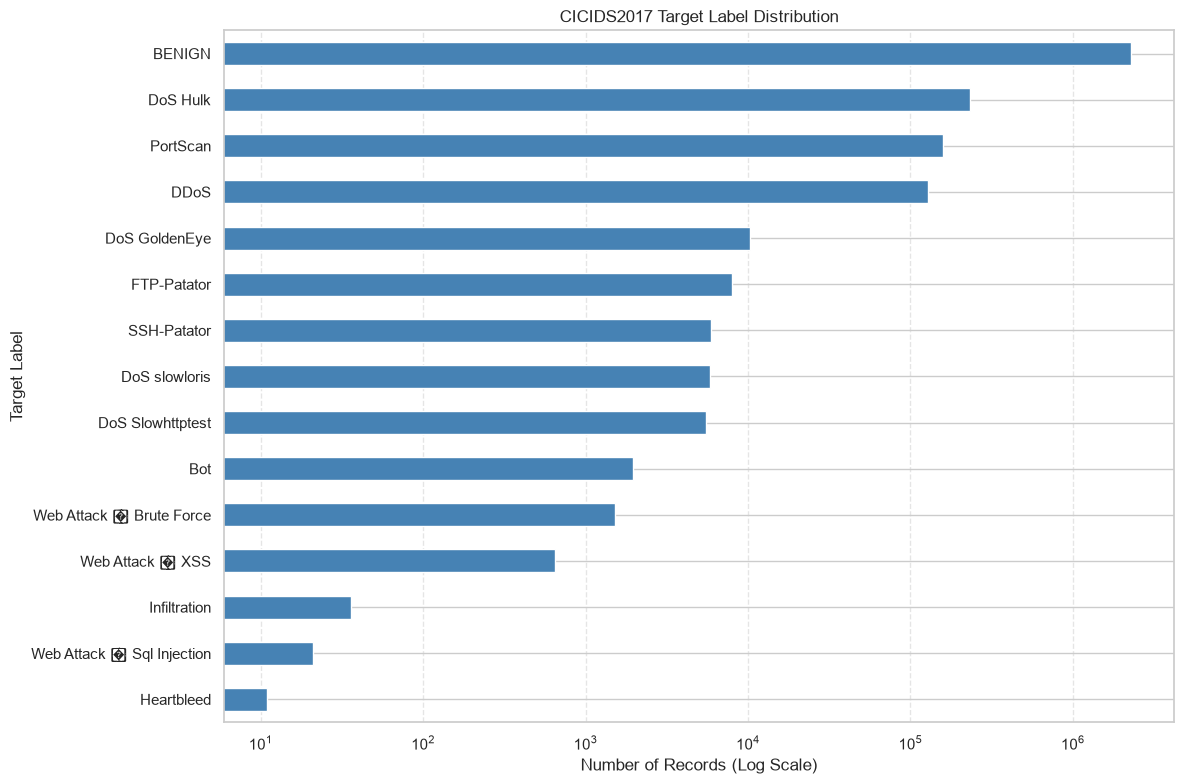

In [12]:
# Cell 12: Visualize target label distribution

plt.figure(figsize=(12, 8))

label_counts.sort_values().plot(
    kind="barh",
    logx=True,
    color="steelblue"
)

plt.title("CICIDS2017 Target Label Distribution")
plt.xlabel("Number of Records (Log Scale)")
plt.ylabel("Target Label")
plt.grid(axis="x", linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

In [13]:
# Cell 13: Analyze row contribution by source file

file_summary = pd.DataFrame(file_row_counts)

# Calculate each file's contribution to the merged dataset
file_summary["Percentage (%)"] = (
    file_summary["Rows"] / len(df) * 100
).round(2)

print("ROW CONTRIBUTION BY SOURCE FILE\n")

display(
    file_summary.sort_values(
        by="Rows",
        ascending=False
    ).reset_index(drop=True)
)

print(f"\nTotal rows across all files: {file_summary['Rows'].sum():,}")
print(f"Rows in merged dataset:      {len(df):,}")
print(
    "Row counts match:",
    file_summary["Rows"].sum() == len(df)
)

ROW CONTRIBUTION BY SOURCE FILE



,File Name,Rows,Columns,Percentage (%)
0,Wednesday-workingHours.pcap_ISCX.csv,692703,79,24.47
1,Monday-WorkingHours.pcap_ISCX.csv,529918,79,18.72
2,Tuesday-WorkingHours.pcap_ISCX.csv,445909,79,15.75
3,Thursday-WorkingHours-Afternoon-Infilteration....,288602,79,10.20
4,Friday-WorkingHours-Afternoon-PortScan.pcap_IS...,286467,79,10.12
5,Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv,225745,79,7.97
6,Friday-WorkingHours-Morning.pcap_ISCX.csv,191033,79,6.75
7,Thursday-WorkingHours-Morning-WebAttacks.pcap_...,170366,79,6.02



Total rows across all files: 2,830,743
Rows in merged dataset:      2,830,743
Row counts match: True


In [15]:
# Cell 15: Numerical feature quality summary

numeric_df = df.select_dtypes(include="number")

# Count missing values
missing_counts = numeric_df.isna().sum()

# Count positive and negative infinity
positive_inf_counts = numeric_df.eq(np.inf).sum()
negative_inf_counts = numeric_df.eq(-np.inf).sum()

# Count negative values, excluding infinite values
negative_counts = (
    numeric_df.lt(0)
    & np.isfinite(numeric_df)
).sum()

# Count features with only one unique non-null value
constant_features = numeric_df.nunique(dropna=True)
constant_features = constant_features[constant_features <= 1]

quality_summary = pd.DataFrame({
    "Missing Values": missing_counts,
    "Positive Infinity": positive_inf_counts,
    "Negative Infinity": negative_inf_counts,
    "Negative Finite Values": negative_counts,
    "Unique Values": numeric_df.nunique(dropna=True)
})

# Display only features with at least one issue
issues_summary = quality_summary[
    (quality_summary["Missing Values"] > 0)
    | (quality_summary["Positive Infinity"] > 0)
    | (quality_summary["Negative Infinity"] > 0)
    | (quality_summary["Negative Finite Values"] > 0)
].sort_values(
    by=["Positive Infinity", "Negative Infinity", "Missing Values"],
    ascending=False
)

print("NUMERICAL DATA QUALITY OVERVIEW")
print("-" * 40)
print(f"Numerical features: {numeric_df.shape[1]}")
print(f"Features with missing values: {(missing_counts > 0).sum()}")
print(f"Features containing infinity: "
      f"{((positive_inf_counts + negative_inf_counts) > 0).sum()}")
print(f"Features with negative finite values: {(negative_counts > 0).sum()}")
print(f"Constant numerical features: {len(constant_features)}")

print("\nFEATURES WITH DATA QUALITY FLAGS:")
display(issues_summary)

print("\nCONSTANT FEATURES:")
print(constant_features.index.tolist())

NUMERICAL DATA QUALITY OVERVIEW
----------------------------------------
Numerical features: 78
Features with missing values: 1
Features containing infinity: 2
Features with negative finite values: 13
Constant numerical features: 8

FEATURES WITH DATA QUALITY FLAGS:


,Missing Values,Positive Infinity,Negative Infinity,Negative Finite Values,Unique Values
Flow Packets/s,0,2867,0,115,1240164
Flow Bytes/s,1358,1509,0,85,1593908
Flow Duration,0,0,0,115,1050899
Flow IAT Mean,0,0,0,115,1166311
Flow IAT Max,0,0,0,115,580289
Flow IAT Min,0,0,0,2891,136316
Fwd IAT Min,0,0,0,17,110631
Fwd Header Length,0,0,0,35,3771
Bwd Header Length,0,0,0,22,3945
Fwd Header Length.1,0,0,0,35,3771



CONSTANT FEATURES:
[' Bwd PSH Flags', ' Bwd URG Flags', 'Fwd Avg Bytes/Bulk', ' Fwd Avg Packets/Bulk', ' Fwd Avg Bulk Rate', ' Bwd Avg Bytes/Bulk', ' Bwd Avg Packets/Bulk', 'Bwd Avg Bulk Rate']


In [16]:
# Cell 16: Investigate constant numerical features

constant_feature_names = numeric_df.nunique(dropna=True)
constant_feature_names = constant_feature_names[
    constant_feature_names <= 1
].index.tolist()

constant_summary = pd.DataFrame({
    "Feature": constant_feature_names,
    "Unique Non-Null Values": [
        numeric_df[col].dropna().unique().tolist()
        for col in constant_feature_names
    ],
    "Missing Values": [
        numeric_df[col].isna().sum()
        for col in constant_feature_names
    ],
    "Zero Count": [
        numeric_df[col].eq(0).sum()
        for col in constant_feature_names
    ]
})

print("CONSTANT FEATURE SUMMARY")
print("-" * 40)
display(constant_summary)

print("\nTotal constant numerical features:", len(constant_feature_names))

CONSTANT FEATURE SUMMARY
----------------------------------------


,Feature,Unique Non-Null Values,Missing Values,Zero Count
0,Bwd PSH Flags,[0],0,2830743
1,Bwd URG Flags,[0],0,2830743
2,Fwd Avg Bytes/Bulk,[0],0,2830743
3,Fwd Avg Packets/Bulk,[0],0,2830743
4,Fwd Avg Bulk Rate,[0],0,2830743
5,Bwd Avg Bytes/Bulk,[0],0,2830743
6,Bwd Avg Packets/Bulk,[0],0,2830743
7,Bwd Avg Bulk Rate,[0],0,2830743



Total constant numerical features: 8


In [17]:
# Cell 17: Detailed missing and infinite value analysis

selected_features = [
    col for col in numeric_df.columns
    if numeric_df[col].isna().any()
    or np.isinf(numeric_df[col]).any()
]

issue_details = []

for col in selected_features:
    series = numeric_df[col]

    missing_count = int(series.isna().sum())
    positive_inf_count = int(np.isposinf(series).sum())
    negative_inf_count = int(np.isneginf(series).sum())

    issue_details.append({
        "Feature": col,
        "Missing Count": missing_count,
        "Missing (%)": round(missing_count / len(df) * 100, 5),
        "Positive Infinity": positive_inf_count,
        "Negative Infinity": negative_inf_count,
        "Total Infinite": positive_inf_count + negative_inf_count,
        "Rows with Missing or Infinite": int(
            (series.isna() | np.isinf(series)).sum()
        )
    })

issue_details_df = pd.DataFrame(issue_details)

print("MISSING AND INFINITE VALUE ANALYSIS")
print("-" * 40)
display(issue_details_df)

print("\nTotal rows:", f"{len(df):,}")
print("Data modified: No")

MISSING AND INFINITE VALUE ANALYSIS
----------------------------------------


,Feature,Missing Count,Missing (%),Positive Infinity,Negative Infinity,Total Infinite,Rows with Missing or Infinite
0,Flow Bytes/s,1358,0.04797,1509,0,1509,2867
1,Flow Packets/s,0,0.00000,2867,0,2867,2867



Total rows: 2,830,743
Data modified: No


In [18]:
# Cell 18: Analyze negative finite values

numeric_df = df.select_dtypes(include="number")

negative_summary = []

for col in numeric_df.columns:
    series = numeric_df[col]

    # Count negative values, excluding infinity
    negative_mask = series.lt(0) & np.isfinite(series)
    negative_count = int(negative_mask.sum())

    if negative_count > 0:
        negative_values = series[negative_mask]

        negative_summary.append({
            "Feature": col,
            "Negative Count": negative_count,
            "Negative (%)": round(
                negative_count / len(df) * 100, 4
            ),
            "Minimum Negative Value": negative_values.min(),
            "Maximum Negative Value": negative_values.max()
        })

negative_summary_df = pd.DataFrame(negative_summary)

print("NEGATIVE VALUE ANALYSIS")
print("-" * 40)

display(
    negative_summary_df.sort_values(
        by="Negative Count",
        ascending=False
    ).reset_index(drop=True)
)

print("\nFeatures containing negative finite values:",
      len(negative_summary_df))

NEGATIVE VALUE ANALYSIS
----------------------------------------


,Feature,Negative Count,Negative (%),Minimum Negative Value,Maximum Negative Value
0,Init_Win_bytes_backward,1441552,50.9249,-1.000000e+00,-1.000000e+00
1,Init_Win_bytes_forward,1001189,35.3684,-1.000000e+00,-1.000000e+00
2,Flow IAT Min,2891,0.1021,-1.400000e+01,-1.000000e+00
3,Flow Packets/s,115,0.0041,-2.000000e+06,-1.538462e+05
4,Flow Duration,115,0.0041,-1.300000e+01,-1.000000e+00
5,Flow IAT Mean,115,0.0041,-1.300000e+01,-1.000000e+00
6,Flow IAT Max,115,0.0041,-1.300000e+01,-1.000000e+00
7,Flow Bytes/s,85,0.0030,-2.610000e+08,-4.615385e+05
8,Fwd Header Length,35,0.0012,-3.221223e+10,-1.100000e+01
9,Fwd Header Length.1,35,0.0012,-3.221223e+10,-1.100000e+01



Features containing negative finite values: 13


In [19]:
# Cell 19: Check duplicate records

print("DUPLICATE RECORD ANALYSIS")
print("-" * 40)

duplicate_rows_count = int(df.duplicated(keep=False).sum())
duplicate_excess_count = int(df.duplicated().sum())

print(f"Total records: {len(df):,}")
print(f"Rows belonging to duplicate groups: {duplicate_rows_count:,}")
print(f"Excess duplicate rows: {duplicate_excess_count:,}")

print(
    f"Percentage of excess duplicate rows: "
    f"{duplicate_excess_count / len(df) * 100:.4f}%"
)

print("\nData modified: No")

DUPLICATE RECORD ANALYSIS
----------------------------------------
Total records: 2,830,743
Rows belonging to duplicate groups: 403,550
Excess duplicate rows: 308,381
Percentage of excess duplicate rows: 10.8940%

Data modified: No


Features selected for distribution analysis:
' Flow Duration'
' Total Fwd Packets'
' Packet Length Mean'
' Flow IAT Mean'
' Average Packet Size'


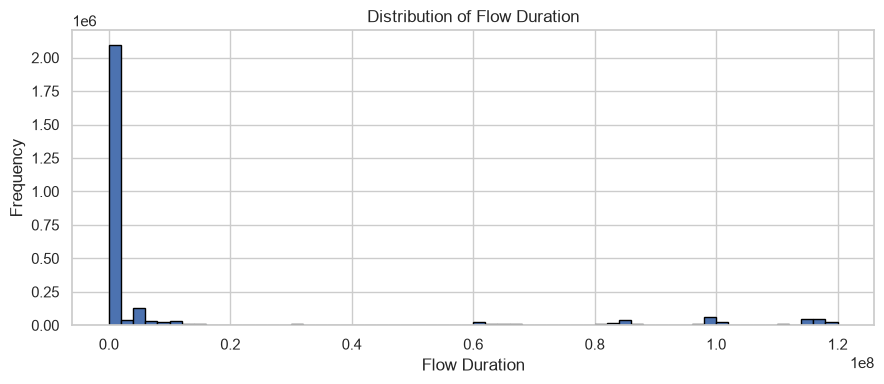

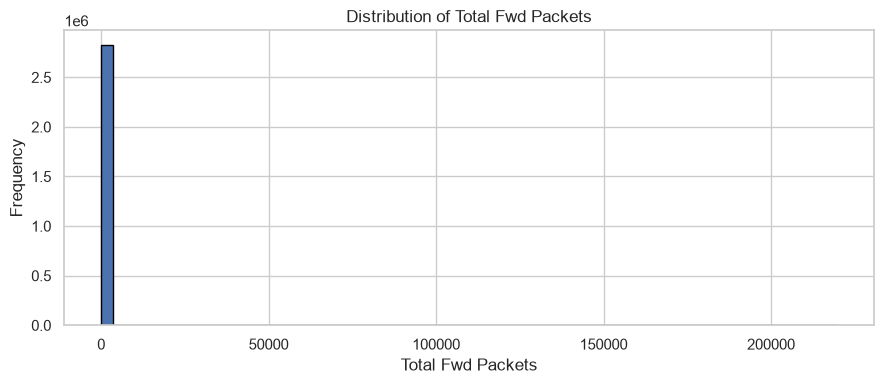

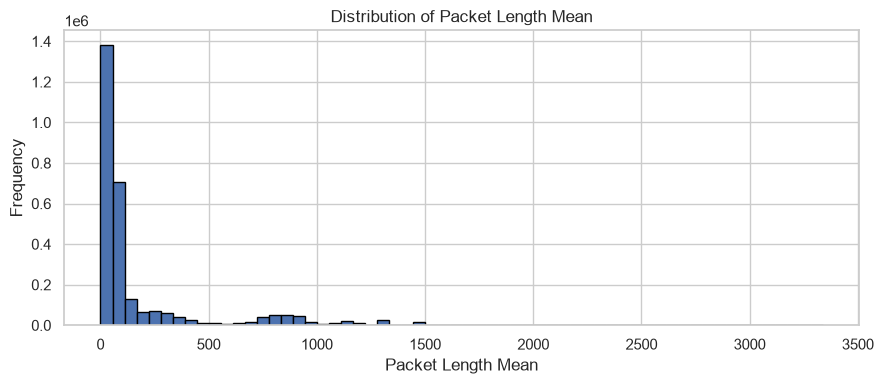

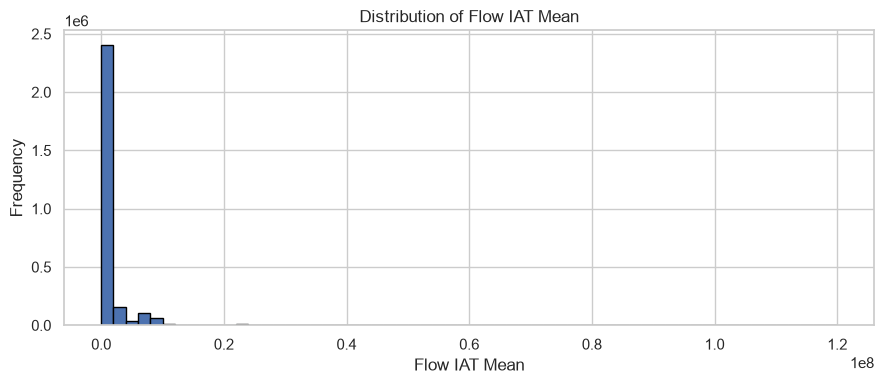

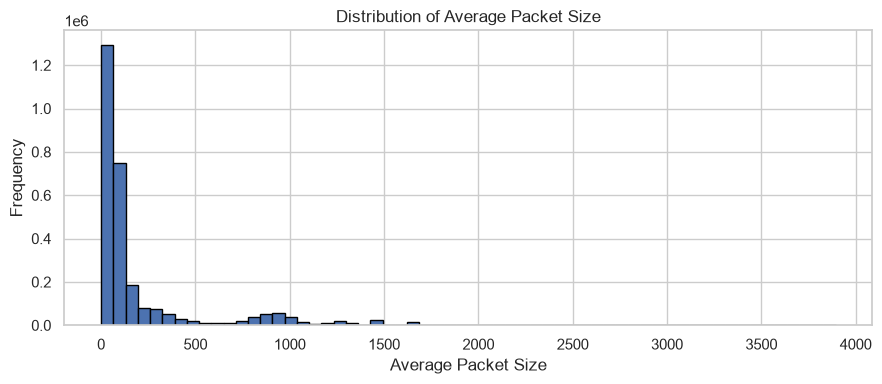

In [20]:
# Cell 20: Visualize representative numerical feature distributions

selected_features = [
    " Flow Duration",
    " Total Fwd Packets",
    " Packet Length Mean",
    " Flow IAT Mean",
    " Average Packet Size"
]

# Identify the exact column names, including any leading spaces
available_features = [
    col for col in selected_features
    if col in df.columns
]

print("Features selected for distribution analysis:")
for col in available_features:
    print(repr(col))

if not available_features:
    print("No exact matches found. Inspect df.columns before plotting.")
else:
    for col in available_features:
        values = df[col].replace([np.inf, -np.inf], np.nan).dropna()

        plt.figure(figsize=(9, 4))
        plt.hist(values, bins=60, edgecolor="black")
        plt.title(f"Distribution of {col.strip()}")
        plt.xlabel(col.strip())
        plt.ylabel("Frequency")
        plt.tight_layout()
        plt.show()

Sample size: 100,000
Traffic type counts:


Traffic Type
BENIGN    80263
ATTACK    19737
Name: count, dtype: int64

d:\ThreatTrace\.venv\Lib\site-packages\seaborn\categorical.py:700: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  artists = ax.bxp(**boxplot_kws)


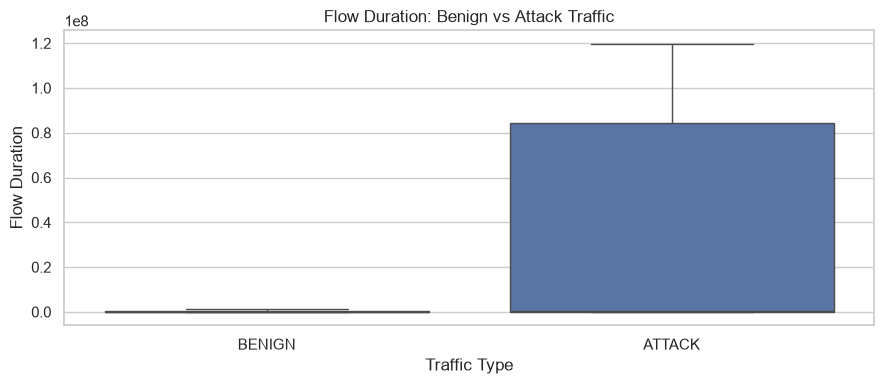

d:\ThreatTrace\.venv\Lib\site-packages\seaborn\categorical.py:700: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  artists = ax.bxp(**boxplot_kws)


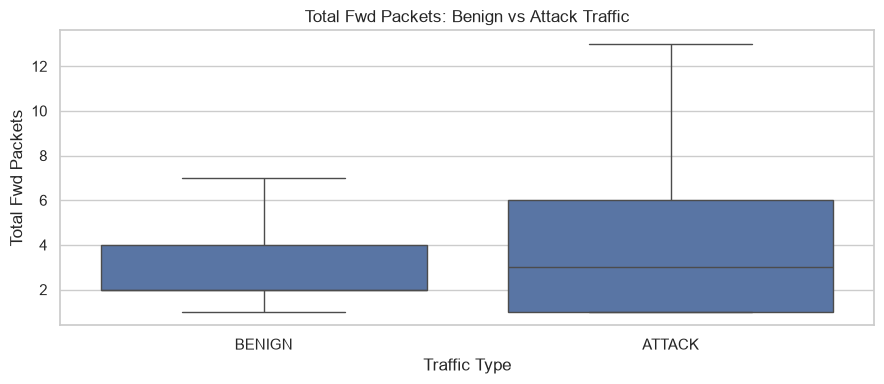

d:\ThreatTrace\.venv\Lib\site-packages\seaborn\categorical.py:700: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  artists = ax.bxp(**boxplot_kws)


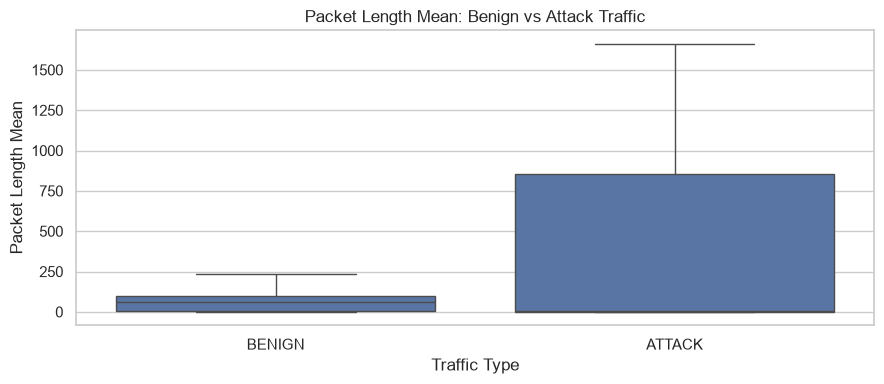

d:\ThreatTrace\.venv\Lib\site-packages\seaborn\categorical.py:700: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  artists = ax.bxp(**boxplot_kws)


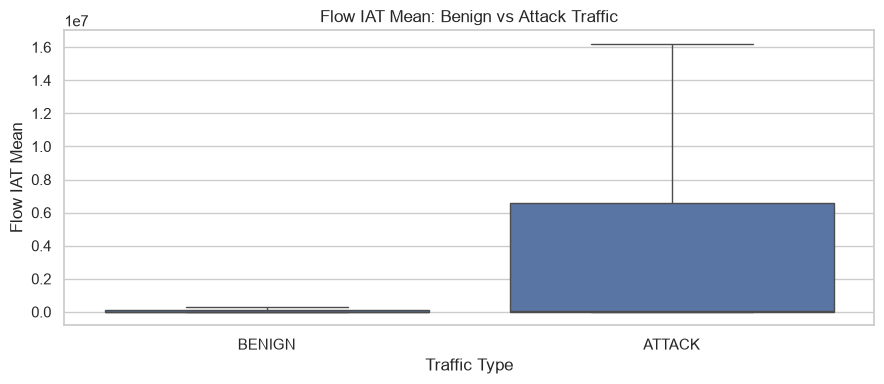

d:\ThreatTrace\.venv\Lib\site-packages\seaborn\categorical.py:700: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  artists = ax.bxp(**boxplot_kws)


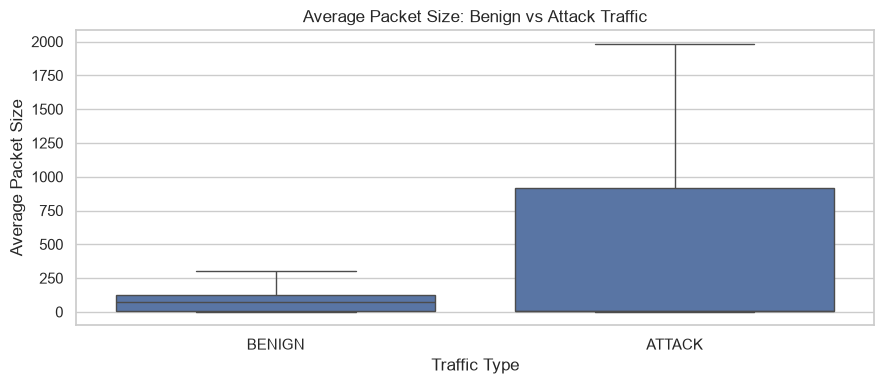

In [21]:
# Cell 21: Compare selected features by traffic label

target_col = " Label"

selected_features = [
    " Flow Duration",
    " Total Fwd Packets",
    " Packet Length Mean",
    " Flow IAT Mean",
    " Average Packet Size"
]

available_features = [
    col for col in selected_features
    if col in df.columns
]

# Use a reproducible sample for visualization
sample_size = min(100_000, len(df))

eda_sample = df.sample(
    n=sample_size,
    random_state=42
)

# Replace infinite values only in the plotting copy
plot_sample = eda_sample[
    available_features + [target_col]
].copy()

plot_sample[available_features] = plot_sample[
    available_features
].replace([np.inf, -np.inf], np.nan)

# Convert labels into two broad groups for comparison
plot_sample["Traffic Type"] = np.where(
    plot_sample[target_col] == "BENIGN",
    "BENIGN",
    "ATTACK"
)

print("Sample size:", f"{len(plot_sample):,}")
print("Traffic type counts:")
display(plot_sample["Traffic Type"].value_counts())

for col in available_features:
    plt.figure(figsize=(9, 4))

    sns.boxplot(
        data=plot_sample,
        x="Traffic Type",
        y=col,
        showfliers=False
    )

    plt.title(f"{col.strip()}: Benign vs Attack Traffic")
    plt.xlabel("Traffic Type")
    plt.ylabel(col.strip())
    plt.tight_layout()
    plt.show()

d:\ThreatTrace\.venv\Lib\site-packages\seaborn\matrix.py:243: PendingDeprecationWarning: The set_bad function will be deprecated in a future version. Use cmap.with_extremes(bad=...) or Colormap(bad=...) instead.
  self.cmap.set_bad(bad)


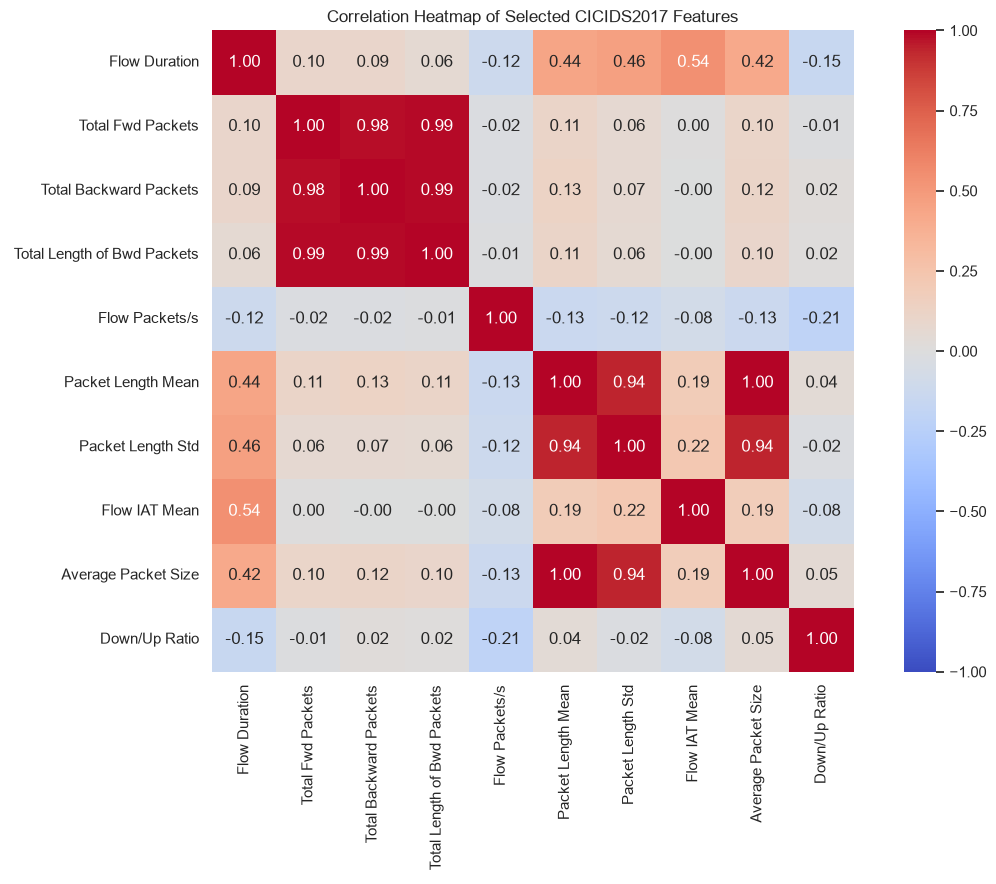

In [22]:
# Cell 22: Correlation analysis of selected numerical features

selected_features = [
    " Flow Duration",
    " Total Fwd Packets",
    " Total Backward Packets",
    " Total Length of Fwd Packets",
    " Total Length of Bwd Packets",
    " Flow Bytes/s",
    " Flow Packets/s",
    " Packet Length Mean",
    " Packet Length Std",
    " Flow IAT Mean",
    " Average Packet Size",
    " Down/Up Ratio"
]

# Keep only columns that exist exactly as named
available_features = [
    col for col in selected_features
    if col in df.columns
]

# Use a reproducible sample to reduce computational cost
corr_sample = df[available_features].sample(
    n=min(50_000, len(df)),
    random_state=42
).replace([np.inf, -np.inf], np.nan)

# Calculate correlations for exploratory analysis
correlation_matrix = corr_sample.corr()

plt.figure(figsize=(12, 9))

sns.heatmap(
    correlation_matrix,
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1,
    annot=True,
    fmt=".2f",
    square=True
)

plt.title("Correlation Heatmap of Selected CICIDS2017 Features")
plt.tight_layout()
plt.show()

In [23]:
# Cell 23: Consolidated EDA findings

eda_findings = pd.DataFrame([
    {
        "Analysis": "Merged dataset",
        "Finding": f"{len(df):,} rows and {df.shape[1]} columns"
    },
    {
        "Analysis": "Source files",
        "Finding": f"{len(csv_files)} CSV files merged successfully"
    },
    {
        "Analysis": "Target classes",
        "Finding": f"{df[target_col].nunique(dropna=False)} classes"
    },
    {
        "Analysis": "Class imbalance",
        "Finding": (
            f"BENIGN represents "
            f"{df[target_col].eq('BENIGN').mean() * 100:.2f}% of records"
        )
    },
    {
        "Analysis": "Missing values",
        "Finding": (
            f"{int(df.isna().sum().sum()):,} missing cells across the dataset"
        )
    },
    {
        "Analysis": "Infinite values",
        "Finding": (
            f"{int(np.isinf(numeric_df.to_numpy()).sum()):,} "
            "infinite numerical values"
        )
    },
    {
        "Analysis": "Constant numerical features",
        "Finding": f"{len(constant_feature_names)} features"
    },
    {
        "Analysis": "Excess duplicate rows",
        "Finding": f"{int(df.duplicated().sum()):,} rows"
    },
    {
        "Analysis": "Negative values",
        "Finding": (
            f"{len(negative_summary_df)} numerical features "
            "contain negative finite values"
        )
    },
    {
        "Analysis": "Feature distributions",
        "Finding": "Selected features show strong right-skewness"
    },
    {
        "Analysis": "Feature correlations",
        "Finding": "Several feature pairs have very high positive correlations"
    }
])

display(eda_findings)

,Analysis,Finding
0,Merged dataset,"2,830,743 rows and 79 columns"
1,Source files,8 CSV files merged successfully
2,Target classes,15 classes
3,Class imbalance,BENIGN represents 80.30% of records
4,Missing values,"1,358 missing cells across the dataset"
5,Infinite values,"4,376 infinite numerical values"
6,Constant numerical features,8 features
7,Excess duplicate rows,"308,381 rows"
8,Negative values,13 numerical features contain negative finite ...
9,Feature distributions,Selected features show strong right-skewness


In [24]:
# Cell 25: Save merged dataset locally

# Define output directory relative to the notebooks folder
processed_dir = os.path.join("..", "data", "processed")

# Create directory if it does not exist
os.makedirs(processed_dir, exist_ok=True)

# Define output file path
merged_file_path = os.path.join(
    processed_dir,
    "cicids2017_merged.csv"
)

# Save the merged dataset without the DataFrame index
df.to_csv(
    merged_file_path,
    index=False
)

print("Merged dataset saved successfully.")
print("File path:", os.path.abspath(merged_file_path))
print(f"Rows saved: {len(df):,}")
print(f"Columns saved: {len(df.columns)}")
print(f"File size: {os.path.getsize(merged_file_path) / (1024**2):.2f} MB")

Merged dataset saved successfully.
File path: d:\ThreatTrace\data\processed\cicids2017_merged.csv
Rows saved: 2,830,743
Columns saved: 79
File size: 921.44 MB
